# 9. Literatura consultada e implicaciones para el EDA

Se reutilizan los inventarios aportados de Scopus y Web of Science, la preselección previa y los planes de investigación del programa. La tabla siguiente muestra el estado **heredado** del cribado; no representa una búsqueda sistemática nueva. Las cadenas originales, motivos por registro, consulta de IEEE Xplore y segundo revisor no están acreditados en esos archivos. No se inventan para completar una rúbrica.

La consulta dirigida de apoyo al EDA verificó los textos completos de Time-MMD, NSW-EPNews, Tan y colaboradores, y Lago y colaboradores. Sus URLs, versiones, huellas y localizadores de resultados están en `literature/`. No se publican los PDF privados del curso ni los cuerpos de artículos. Una arquitectura mencionada en un resumen no queda validada como baseline.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/manifest.json').exists())
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
from IPython.display import display,Markdown
from colombia_energy import eda
pd.set_option('display.max_rows',35)
pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:.5g}')


,inventario_previo
registros_exportados,855
scopus,562
wos,293
unicos,668
seleccionados,83


,exportación_actual,inventario_previo
Scopus,615,562
Web of Science,293,293


La exportación actual de Scopus contiene **615** identificadores distintos, mientras el inventario previo registra **562**. La diferencia de **53** registros no está conciliada por artículo. Los conteos heredados se preservan como antecedente, no como un PRISMA reproducido desde los archivos actuales.

,resúmenes_preseleccionados_que_mencionan_arquitectura
LSTM,24
GRU,7
RNN,5
MLP,7
CNN,7


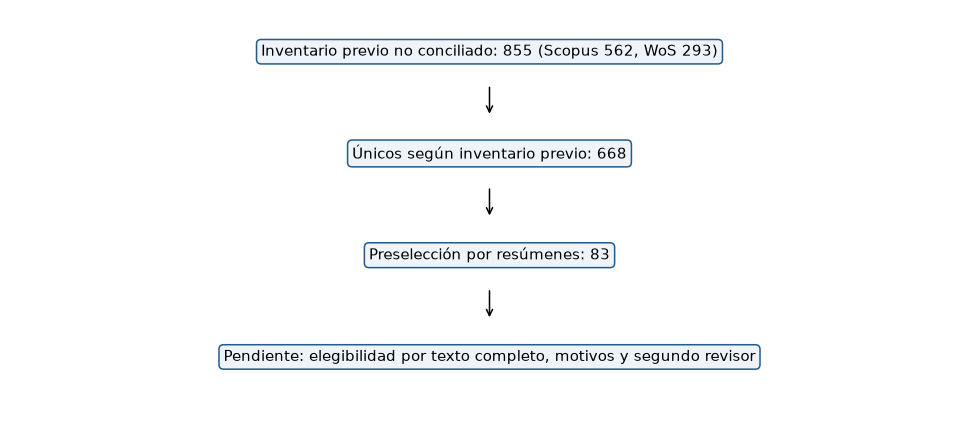

In [2]:
import json
meta=json.loads((ROOT/'literature/inherited_prisma_counts.json').read_text(encoding='utf-8'))
counts=pd.Series({k:meta[k] for k in ['registros_exportados','scopus','wos','unicos','seleccionados']},name='inventario_previo')
eda.table(counts.to_frame(),'literatura_inventario_previo')
audit=json.loads((ROOT/'literature/raw_export_audit.json').read_text(encoding='utf-8'))
eda.table(pd.DataFrame({'exportación_actual':[audit['scopus_current_publication_ids'],audit['wos_current_records']],
    'inventario_previo':[audit['inherited_scopus_count'],audit['inherited_wos_count']]},index=['Scopus','Web of Science']),'literatura_conciliacion_exportaciones')
display(Markdown(f"La exportación actual de Scopus contiene **{audit['scopus_current_publication_ids']}** identificadores distintos, mientras el inventario previo registra **{audit['inherited_scopus_count']}**. La diferencia de **{audit['scopus_difference']}** registros no está conciliada por artículo. Los conteos heredados se preservan como antecedente, no como un PRISMA reproducido desde los archivos actuales."))
selected=pd.read_csv(ROOT/'literature/inherited_selected_83.csv')
freq=selected[['LSTM','GRU','RNN','MLP','CNN']].sum().to_frame('resúmenes_preseleccionados_que_mencionan_arquitectura')
eda.table(freq,'literatura_menciones_no_baselines')
fig,ax=eda.plt.subplots(figsize=(9,4));ax.axis('off')
boxes=[(.9,f"Inventario previo no conciliado: {meta['registros_exportados']} (Scopus {meta['scopus']}, WoS {meta['wos']})"),
       (.65,f"Únicos según inventario previo: {meta['unicos']}"),(.4,f"Preselección por resúmenes: {meta['seleccionados']}"),
       (.15,'Pendiente: elegibilidad por texto completo, motivos y segundo revisor')]
for y,label in boxes:ax.text(.5,y,label,ha='center',va='center',bbox=dict(boxstyle='round',fc='#eef4fa',ec='#245b8d'))
for y in [.82,.57,.32]:ax.annotate('',xy=(.5,y-.08),xytext=(.5,y),arrowprops=dict(arrowstyle='->'))
eda.figure(fig,'flujo_bibliografico_parcial')


## Resultados comprobados en texto completo

La tabla es una **extracción puntual**, no un ranking entre artículos: cambian moneda, escala, periodo, horizonte y protocolo. No son resultados de los modelos colombianos. La diferencia entre añadir texto exógeno y usar un LLM sobre números es central.


In [3]:
verified=pd.read_csv(ROOT/'literature/verified_extracts.csv')
eda.table(verified,'literatura_resultados_verificados')

,referencia,problema,dataset,modelos_comparados_verificados,metrica,valores_reportados,localizador,url,limite_de_comparabilidad
0,"Liu et al. (2024), Time-MMD",Pronóstico multimodal,Energy: gasolina semanal,DLinear uni/multimodal; otros backbones,MSE,H=12: 0.26 unimodal; 0.22 multimodal,"Tabla 12, p.33 del PDF v2",https://arxiv.org/pdf/2406.08627v2,Escala del benchmark; no COP ni precio eléctrico.
1,Tan et al. (2024),Ablación del LLM sobre series numéricas,ETTh1; promedio de horizontes de la tabla,Time-LLM; sin LLM; atención; Transformer,MSE,Time-LLM 0.417; sin LLM 0.405,"Tabla 3, p.6 del PDF v2",https://arxiv.org/pdf/2406.16964v2,No evalúa añadir noticias exógenas; no demuest...
2,"Bi et al. (2025), NSW-EPNews",Pronóstico de precio eléctrico con texto/clima,NSW 2015–2024; subconjunto reciente 50%,ARIMA; LR; XGBoost; ChatGPT-4o; Gemini 1.5 Pro,MAE,ARIMA 54.579; ChatGPT-4o zero-shot 53.646; abl...,"Tabla 2, p.7; definición de ablation tabla 1",https://arxiv.org/pdf/2506.11050v1,Ablación elimina noticias y temperatura; no aí...
3,Lago et al. (2021),Precio eléctrico del día siguiente,"NP, ejemplo de cinco mercados",DNN feed-forward; LEAR regularizado,MAE,DNN3 1.712; LEAR84 1.952,"Tabla 2, p.15",https://doi.org/10.1016/j.apenergy.2021.116983,Unidades del mercado original; no trasladar el...
4,"Nguyen et al. (2026), REST-TS",Fusión multimodal y text collapse,"Time-MMD; TimeBridge, promedio de horizontes",Unimodal; MM-TSFLib; TaTS; REST-TS,MSE,Energy: TaTS 0.297; REST-TS 0.261. Traffic: 0....,"Tabla 1, p.7",https://arxiv.org/pdf/2606.19413,No mejora en toda combinación; separar utilida...
5,"Su et al. (2025), TeR-TSF",Refuerzo de texto para pronóstico,"Time-MMD, promedio entre dominios",TSF-only; TSF+Text; TSF+TeR; TeR-TSF,MSE,"0.771; 0.768; 0.953; 0.631, respectivamente","Tabla 2, p.7",https://arxiv.org/pdf/2509.00687,Promedios de dominios y configuración del artí...
6,"Liu et al. (2026), TimesX",Auditoría de evaluación multimodal,"Time-MMD, reemplazo de contexto textual",LLM con contexto original y con contexto de lo...,MASE agregada geométrica,Contexto original 0.906; contexto de autores 0...,Tabla 3 y apéndice S,https://arxiv.org/pdf/2607.06973,"El contraste cambia contexto, no sólo arquitec..."


**Time-MMD.** El trabajo construye series numéricas y texto alineado en varios dominios y compara versiones uni/multimodales. La tabla de Energy permite comprobar ganancias concretas de DLinear al añadir la rama textual. Es gasolina semanal, no electricidad colombiana: el resultado motiva contrastar fusión, no garantiza transferencia. Para este proyecto importan cobertura, fechas de publicación y versión exacta. [Texto completo, apéndices D.4, K y tabla 12](https://arxiv.org/pdf/2406.08627v2).

**Tan y colaboradores.** Las ablaciones quitan o reemplazan el LLM en modelos alimentados por series numéricas. El resultado no demuestra que las noticias exógenas carezcan de valor. Motiva referencias numéricas fuertes y ablaciones del componente costoso, con incertidumbre y presupuesto comparable. [Texto completo, secciones 3–4 y tabla 3](https://arxiv.org/pdf/2406.16964v2).

**NSW-EPNews.** Combina precios de electricidad, temperatura y noticias. La tabla de resultados muestra que el efecto depende del modelo y de la configuración. Su prompt de ablación retira noticias y temperatura simultáneamente; ese contraste no aísla el aporte exclusivo del texto. Aquí el futuro contraste debe mantener constantes las variables numéricas y añadir sólo texto. Se conservarán salidas numéricas de dimensión fija y se auditará disponibilidad. [Texto completo, secciones 3–4, tablas 1–2 y apéndice C](https://arxiv.org/pdf/2506.11050v1).

**Lago y colaboradores.** El benchmark eléctrico compara redes feed-forward y regresión autorregresiva regularizada en varios mercados. Sus recomendaciones apoyan separar evaluación temporal, comparar referencias fuertes y usar errores interpretables junto con medidas relativas. Los valores de otros mercados no son un umbral en COP. [Texto completo, secciones 3–6 y tabla 2](https://doi.org/10.1016/j.apenergy.2021.116983).

**REST-TS.** La auditoría de la rama textual examina si cambia con el contenido y propone supervisión sobre residuales. Sus tablas incluyen mejoras y regresiones: añadir una rama no basta para atribuir una ganancia al texto. Motiva ablaciones de contenido placebo y comparaciones con el mismo backbone en E2/E3. Una futura propuesta residual deberá distinguir su mecanismo de este antecedente. [Texto completo, secciones 3–4 y tabla 1](https://arxiv.org/pdf/2606.19413).

**TeR-TSF.** Compara texto original, texto generado y texto reforzado por recompensa. Los resultados muestran que generar texto sin el esquema de refuerzo puede empeorar la predicción. Este EDA conserva titulares originales y no rellena huecos con generación. La recompensa y cualquier ajuste posterior deberán usar sólo entrenamiento. [Texto completo, método y tabla 2](https://arxiv.org/pdf/2509.00687).

**TimesX.** Su estudio de sustitución de contexto ilustra que el contenido disponible y la contaminación de preentrenamiento pueden alterar la comparación. Motiva documentar versiones, igualar contexto y no confundir una mejora arquitectónica con información adicional. La política ampliada autorizada aquí no resuelve por sí sola esos riesgos. [Texto completo, sección 3, tabla 3 y apéndice S](https://arxiv.org/pdf/2607.06973).

## Material del programa

Los planes de volatilidad, riesgo, energía con recuperación adaptativa y transferencia son **guías internas, no resultados empíricos publicados**. El plan energético, sección 7.2, pide documentar fuentes, cobertura serie/documentos, calidad, diccionario y sesgo de estaciones/reportes; esos puntos se aplican en este libro. El plan de transferencia recuerda distinguir dominios: pasar de gasolina o finanzas al precio eléctrico requiere evidencia. Las instrucciones de esos planes no reemplazan la solicitud del autor ni las pautas del curso; no se trasladan sus tareas de VaR, generación eólica o publicaciones al presente EDA.

También se revisó la lista de papers y datasets aportada en Excel. Sus notas se conservan como inventario de lectura; las afirmaciones anteriores se verificaron nuevamente en los artículos completos. Los demás títulos de esa lista no se presentan como resultados verificados de esta revisión.

## Consecuencia para E1 y fases posteriores

**E1 usará sólo entradas numéricas.** MLP, LSTM y CNN1D son candidatos de familias con sesgos distintos; la frecuencia de menciones en resúmenes no cierra su elección como los tres baselines exigidos. Falta verificar para esa selección las arquitecturas comparativas de los estudios elegibles. No se implementan ni entrenan aquí esos tres modelos.

El texto queda reservado para E2/E3. Una fusión o un retriever deberán aprender con entrenamiento, sin clasificación temática previa del corpus. La pregunta falsable futura es si añadir texto reduce el error sobre el **mismo bloque numérico** y los mismos orígenes, bajo una política temporal explícita. El escenario ampliado autorizado puede contener fuga por revisiones, que deberá declararse y contrastarse; no se convierte en un resultado operacional por incluir más registros.


In [4]:
eda.decision('Derivar el preprocesamiento del EDA numérico de train; registrar cobertura y políticas temporales sin aprender temas globales.', 'E1 exclusivamente numérico; en E2/E3 comparar el mismo bloque numérico con/sin texto y ablaciones de fusión.', 'No transportar métricas entre datasets; fijar presupuesto, semillas, margen y protocolo antes del benchmark.', 'Revisión sistemática y extracción final de tres baselines aún incompletas. Una ganancia publicada no acredita ganancia en Colombia.')

### Implicaciones del análisis

- **Preprocesamiento:** Derivar el preprocesamiento del EDA numérico de train; registrar cobertura y políticas temporales sin aprender temas globales.
- **Arquitectura:** E1 exclusivamente numérico; en E2/E3 comparar el mismo bloque numérico con/sin texto y ablaciones de fusión.
- **Validación:** No transportar métricas entre datasets; fijar presupuesto, semillas, margen y protocolo antes del benchmark.
- **Riesgos:** Revisión sistemática y extracción final de tres baselines aún incompletas. Una ganancia publicada no acredita ganancia en Colombia.